# 4–5. PDF Data Cleaning and Dataset Construction

<span style="font-size:24px;">

**A standalone classroom workflow using real weekly water-quality reports**

PDF → table extraction → data cleaning → integration → validation → CSV

</span>

<div class="alert alert-block alert-info" style="border:1px solid #bce8f1; background:#d9edf7; padding:1em; border-radius:4px;">
  <p style="font-size:24px; margin:0;">Learning goals and classroom workflow</p>
</div>

<span style="font-size:20px;">

This lesson is designed for graduate students. By the end, you will be able to:

1. inspect and extract a real PDF table;
2. retain provenance and extraction failures;
3. clean, standardize, and quality-control observations;
4. build observation, metadata, availability, statistical, and documentation tables;
5. validate and publish a reproducible environmental dataset.

We first process one PDF manually, then reuse the same functions for all reports. No paid API or network connection is required.

</span>

## 4. Data Cleaning



### 4.1 Introduction: From PDF Reports to Structured Data

A PDF is a presentation format, not a database. The reports used here contain multi-row headers, repeated headers on every page, blank cells that visually inherit labels from previous rows, and missing measurements represented by several dash characters. We therefore preserve a **raw extracted table** before creating cleaned observations.

<div class="alert alert-block alert-info" style="border:1px solid #bce8f1; background:#d9edf7; padding:1em; border-radius:4px;">
  <p style="font-size:24px; margin:0;">Important distinction: reporting periods are not sampling timestamps</p>
</div>

These reports summarize a weekly reporting period. They do not provide the exact timestamp of each measurement used in the weekly value. We therefore store `ReportPeriodStart` and `ReportPeriodEnd`, but keep `SamplingDate` and `MeasurementTimestamp` missing. Weekly report coverage must not be described as daily or hourly completeness.

### 4.2 Explore the PDF Directory

Run this notebook from the `Date2` directory. If you intentionally run it elsewhere, set `PROJECT_DIR_OVERRIDE` to the absolute `Date2` path. The guard below prevents accidental output in an unrelated folder.

In [1]:
from pathlib import Path
import hashlib
import re
import textwrap
import warnings

import numpy as np
import pandas as pd
import pdfplumber
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Use None when the notebook is launched from Date2.
PROJECT_DIR_OVERRIDE = None
PROJECT_DIR = Path(PROJECT_DIR_OVERRIDE).expanduser().resolve() if PROJECT_DIR_OVERRIDE else Path.cwd().resolve()

DATA_DIR = PROJECT_DIR / "weekly_PDF"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Expected a weekly_PDF directory under {PROJECT_DIR}. "
        "Run the notebook from Date2 or set PROJECT_DIR_OVERRIDE explicitly."
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def report_number(path):
    """Sort issue 2 before issue 10; ordinary filename sorting does not."""
    match = re.search(r"第(\d+)期", path.stem)
    return int(match.group(1)) if match else float("inf")

pdf_files = sorted(DATA_DIR.glob("*.pdf"), key=lambda path: (report_number(path), path.name))
print(f"Project directory: {PROJECT_DIR}")
print(f"PDF files found: {len(pdf_files)}")
for path in pdf_files[:5]:
    print(" -", path.name)
if len(pdf_files) > 5:
    print(f" ... and {len(pdf_files) - 5} more")

Project directory: /Volumes/Kioxia/Users/jingyu/Documents/SCNU/教学/研究生课程_AI for 环境数据可视化/Date2
PDF files found: 33
 - 2014年第1期.pdf
 - 2014年第2期.pdf
 - 2014年第3期.pdf
 - 2014年第4期.pdf
 - 2014年第5期.pdf
 ... and 28 more


### 4.3 Extract Tables from a Single PDF

We inspect the first report before writing a batch pipeline. `pdfplumber` returns each table as a list of rows. Page 1 contains narrative text; the monitoring table begins on page 2.

In [2]:
representative_pdf = pdf_files[0]
with pdfplumber.open(representative_pdf) as pdf:
    first_page_text = pdf.pages[0].extract_text() or ""
    representative_tables = pdf.pages[1].extract_tables()

print(first_page_text[:900])
print(f"\nTables detected on page 2: {len(representative_tables)}")
display(pd.DataFrame(representative_tables[0][:7]))

全 国 主 要 流 域 重 点 断 面 水 质 自 动 监 测 周 报
2014年 第 1期
中国环境监测总站 2014 年 1月 7
日
2014 年第 1周（ 2013 年 12 月 30 日～ 1月 5日），全国主要水系 131个重点断面水质自动监测站八项指标（水温、
pH 、浊度、溶解氧、电导率、高锰酸盐指数、氨氮和总有机碳）的监测结果表明：Ⅰ～Ⅲ类水质的断面为 101个，占 80% ；Ⅳ类水
质的断面为 9个，占 7%；Ⅴ类水质的断面为 7个，占 5%；劣Ⅴ类水质的断面为 10 个，占 8%。松花江流域松花江肇源站和同
江站、额尔古纳河呼伦贝尔黑山头站、乌苏里江抚远乌苏镇站因洪灾造成设备故障未监测。
本周淮河流域洪汝河驻马店班台断面水质状况有所好转；海河流域洋河张家口八号桥断面，淮河流域颖河界首七渡口断面、沱河
淮北小王桥断面、新濉河泗洪大屈断面、邳苍分洪道西偏泓邳州邳苍艾山西大桥断面、白马河临沂涝沟桥断面，珠江流域珠江广州长洲
断面，水质状况有所下降。水质状况的改变主要是由于水体中高锰酸盐指数、氨氮和溶解氧浓度变化造成的。
具体监测数据参见全国主要流域重点断面 2014 年第 1周水质状况表。
主 送：监测司（3）、污防司（3）、环监局（1）、宣教司（1） 中国环境监测
总站
全国主要流域重点断面 2014年第 1周水质状况表
1

Tables detected on page 2: 1


,0,1,2,3,4,5,6,7,8,9,10,11
0,序号,水系,河流名称,点位名称,断面情况,评价因子（单位：mg/L）,None,None,None,水质类别,None,主要污染指标
1,None,None,None,None,None,pH*,DO,COD\nMn,NH -N\n3,本周,上周,None
2,1,松花江\n流域,松花江,吉林溪浪口,,6.96,13.3,3.1,0.17,Ⅱ,Ⅰ,
3,2,None,None,长春松花江村,,6.88,8.24,4.1,0.57,Ⅲ,Ⅲ,
4,3,None,None,松原松林,吉-黑省界,8.02,8.00,5.5,0.90,Ⅲ,Ⅲ,
5,4,None,None,肇源,,—,—,—,—,—,—,
6,5,None,None,同江,入黑龙江前,—,—,—,—,—,—,


The table has two header rows. The four reported numerical indicators are pH, dissolved oxygen (DO), permanganate index (CODMn), and ammonia nitrogen (NH3-N). The merged heading says mg/L, but pH is dimensionless; we correct that unit during standardization.

### 4.4 Convert Extracted Tables into Pandas DataFrames

The functions below parse report metadata, normalize PDF text, and keep the source PDF, page, table number, and source row. Empty river-basin and river cells are carried forward because the PDF visually uses merged cells.

In [3]:
MISSING_TOKENS = {"", "-", "—", "–", "−", "★", "None", "nan"}

def compact_text(value):
    """Remove PDF line breaks and repeated whitespace without translating the source."""
    if value is None:
        return ""
    return re.sub(r"\s+", "", str(value)).strip()

def parse_report_metadata(text, filename):
    """Parse issue metadata, including reporting periods that cross a year boundary."""
    normalized = re.sub(r"\s+", "", text)
    year_match = re.search(r"(\d{4})年第\d+期", normalized)
    week_match = re.search(r"(\d{4})年第(\d+)周", normalized)
    issue_match = re.search(r"(\d{4})年第(\d+)期", normalized)
    date_match = re.search(r"(\d{1,2})月(\d{1,2})日[～~至](\d{1,2})月(\d{1,2})日", normalized)
    expected_match = re.search(r"全国主要水系(\d+)个重点断面", normalized)

    report_year = int(year_match.group(1)) if year_match else None
    week = int(week_match.group(2)) if week_match else None
    issue = int(issue_match.group(2)) if issue_match else None
    date_parse_method = "unavailable"

    if date_match and report_year:
        m1, d1, m2, d2 = map(int, date_match.groups())
        # A January report can begin in December of the preceding calendar year.
        start_year = report_year - 1 if m1 > m2 else report_year
        end_year = report_year
        start = pd.Timestamp(start_year, m1, d1)
        end = pd.Timestamp(end_year, m2, d2)
        date_parse_method = "reported_month_day_with_cross_year_rule"
    elif week_match:
        iso_year = int(week_match.group(1))
        start = pd.Timestamp.fromisocalendar(iso_year, week, 1)
        end = start + pd.Timedelta(days=6)
        date_parse_method = "iso_week_fallback"
    else:
        start = end = pd.NaT

    return {
        "SourcePDF": filename,
        "ReportYear": report_year,
        "ReportIssue": issue,
        "ReportWeek": week,
        "ReportPeriodStart": start,
        "ReportPeriodEnd": end,
        "DateParseMethod": date_parse_method,
        "ExpectedStationsFromNarrative": int(expected_match.group(1)) if expected_match else np.nan,
        "ReportTitle": f"National Key-Section Water-Quality Automatic Monitoring Weekly Report, issue {issue}",
        "SourceProvider": "China National Environmental Monitoring Centre (中国环境监测总站)",
    }

def extract_pdf_tables(pdf_path):
    """Return a raw wide table plus a transparent processing-log record."""
    records, page_notes = [], []
    last_basin = last_river = ""
    with pdfplumber.open(pdf_path) as pdf:
        first_text = pdf.pages[0].extract_text() or ""
        meta = parse_report_metadata(first_text, pdf_path.name)
        for page_number, page in enumerate(pdf.pages, start=1):
            tables = page.extract_tables() or []
            if page_number > 1 and not tables:
                page_notes.append(f"page {page_number}: no table detected")
            for table_number, table in enumerate(tables, start=1):
                for source_row, row in enumerate(table, start=1):
                    row = (list(row) + [None] * 12)[:12]
                    serial_text = compact_text(row[0])
                    if not re.fullmatch(r"\d+", serial_text):
                        continue  # removes both repeated header rows
                    basin = compact_text(row[1])
                    river = compact_text(row[2])
                    station = compact_text(row[3])
                    section_context = compact_text(row[4])
                    if basin and basin != "流域":
                        last_basin = basin
                    if river:
                        last_river = river
                    records.append({
                        **meta,
                        "PDFPage": page_number,
                        "PDFTable": table_number,
                        "PDFSourceRow": source_row,
                        "StationSerial": int(serial_text),
                        "RiverBasin": last_basin or np.nan,
                        "RiverName": last_river or np.nan,
                        "MonitoringLocationName": station or np.nan,
                        "SectionContext": section_context or np.nan,
                        "pH_raw": compact_text(row[5]),
                        "DO_raw": compact_text(row[6]),
                        "CODMn_raw": compact_text(row[7]),
                        "NH3N_raw": compact_text(row[8]),
                        "WaterQualityClassCurrent": compact_text(row[9]) or np.nan,
                        "WaterQualityClassPrevious": compact_text(row[10]) or np.nan,
                        "MainPollutants": compact_text(row[11]) or np.nan,
                        "ExtractionMethod": "pdfplumber.extract_tables",
                    })
    raw = pd.DataFrame(records)
    max_serial = int(raw["StationSerial"].max()) if not raw.empty else 0
    expected = meta["ExpectedStationsFromNarrative"]
    status = "success"
    if raw.empty:
        status = "failed_manual_review"
    elif pd.notna(expected) and max_serial < int(expected):
        status = "partial_manual_review"
        page_notes.append(f"maximum extracted serial {max_serial} < narrative station count {int(expected)}")
    log = {
        **meta,
        "PDFPages": page_number,
        "RawStationRows": len(raw),
        "MaxStationSerial": max_serial,
        "ExtractionStatus": status,
        "ReviewNotes": "; ".join(page_notes) if page_notes else "",
    }
    return raw, log

one_raw, one_log = extract_pdf_tables(representative_pdf)
display(one_raw.head())
display(pd.DataFrame([one_log]))

,SourcePDF,ReportYear,ReportIssue,ReportWeek,ReportPeriodStart,ReportPeriodEnd,DateParseMethod,ExpectedStationsFromNarrative,ReportTitle,SourceProvider,...,MonitoringLocationName,SectionContext,pH_raw,DO_raw,CODMn_raw,NH3N_raw,WaterQualityClassCurrent,WaterQualityClassPrevious,MainPollutants,ExtractionMethod
0,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,吉林溪浪口,NaN,6.96,13.3,3.1,0.17,Ⅱ,Ⅰ,NaN,pdfplumber.extract_tables
1,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,长春松花江村,NaN,6.88,8.24,4.1,0.57,Ⅲ,Ⅲ,NaN,pdfplumber.extract_tables
2,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,松原松林,吉-黑省界,8.02,8.00,5.5,0.90,Ⅲ,Ⅲ,NaN,pdfplumber.extract_tables
3,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,肇源,NaN,—,—,—,—,—,—,NaN,pdfplumber.extract_tables
4,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,同江,入黑龙江前,—,—,—,—,—,—,NaN,pdfplumber.extract_tables


,SourcePDF,ReportYear,ReportIssue,ReportWeek,ReportPeriodStart,ReportPeriodEnd,DateParseMethod,ExpectedStationsFromNarrative,ReportTitle,SourceProvider,PDFPages,RawStationRows,MaxStationSerial,ExtractionStatus,ReviewNotes
0,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,7,131,131,success,


### 4.5 Identify and Handle Missing Values

Missing measurements remain missing. A dash or star is not converted to zero because zero is a possible scientific value. We reshape the four indicators to long format so that one row represents one station–indicator–weekly-report observation.

In [4]:
INDICATORS = {
    "pH_raw": ("pH", "dimensionless"),
    "DO_raw": ("Dissolved oxygen", "mg/L"),
    "CODMn_raw": ("Permanganate index", "mg/L"),
    "NH3N_raw": ("Ammonia nitrogen", "mg/L"),
}

def parse_number(value):
    text = compact_text(value)
    if text in MISSING_TOKENS:
        return np.nan
    match = re.fullmatch(r"[<>]?\s*(-?\d+(?:\.\d+)?)", text)
    return float(match.group(1)) if match else np.nan

def wide_to_long(raw):
    id_columns = [c for c in raw.columns if c not in INDICATORS]
    long = raw.melt(id_vars=id_columns, value_vars=list(INDICATORS),
                    var_name="IndicatorSourceColumn", value_name="OriginalValue")
    long["IndicatorsName"] = long["IndicatorSourceColumn"].map(lambda c: INDICATORS[c][0])
    long["Unit"] = long["IndicatorSourceColumn"].map(lambda c: INDICATORS[c][1])
    long["Value"] = long["OriginalValue"].map(parse_number)
    long["OriginalMissingToken"] = long["OriginalValue"].map(compact_text).isin(MISSING_TOKENS)
    return long

one_long = wide_to_long(one_raw)
display(one_long[["MonitoringLocationName", "IndicatorsName", "OriginalValue", "Value", "Unit"]].head(12))
print("Missing measurements:", int(one_long["Value"].isna().sum()))

,MonitoringLocationName,IndicatorsName,OriginalValue,Value,Unit
0,吉林溪浪口,pH,6.96,6.96,dimensionless
1,长春松花江村,pH,6.88,6.88,dimensionless
2,松原松林,pH,8.02,8.02,dimensionless
3,肇源,pH,—,NaN,dimensionless
4,同江,pH,—,NaN,dimensionless
5,白城白沙滩,pH,7.74,7.74,dimensionless
6,吉林敦化新甸,pH,7.15,7.15,dimensionless
7,呼伦贝尔黑山头,pH,—,NaN,dimensionless
8,大兴安岭呼玛,pH,8.15,8.15,dimensionless
9,黑河,pH,7.34,7.34,dimensionless


Missing measurements: 17


### 4.6 Remove Duplicate Records and Repeated Headers

Repeated headers were excluded because their first field is not an integer station serial. We detect duplicates with a key based on report period, station identity, and indicator. Duplicates are logged and only exact duplicate observations are removed automatically.

### 4.7 Standardize Column Names, Dates, Stations, and Units

Station identifiers are deterministic hashes of the reported basin, river, and station text. We do not infer coordinates, province, or site type from a name. This conservative choice prevents plausible-looking but unsupported metadata.

In [5]:
def stable_station_id(row):
    identity = "|".join(compact_text(row.get(c, "")) for c in ["RiverBasin", "RiverName", "MonitoringLocationName"])
    return "ST-" + hashlib.sha1(identity.encode("utf-8")).hexdigest()[:12].upper()

def add_identifiers(df):
    result = df.copy()
    result["MonitoringLocationName"] = result["MonitoringLocationName"].astype("string").str.strip()
    result["MonitoringLocationIdentifier"] = result.apply(stable_station_id, axis=1)
    result["ReportPeriodStart"] = pd.to_datetime(result["ReportPeriodStart"])
    result["ReportPeriodEnd"] = pd.to_datetime(result["ReportPeriodEnd"])
    result["SamplingDate"] = pd.NaT
    result["MeasurementTimestamp"] = pd.NaT
    result["RecordIdentifier"] = (
        result["MonitoringLocationIdentifier"] + "-W" +
        result["ReportWeek"].astype("Int64").astype(str).str.zfill(2) + "-" +
        result["IndicatorsName"].str.replace(r"[^A-Za-z0-9]+", "-", regex=True).str.strip("-").str.upper()
    )
    return result

one_long = add_identifiers(one_long)
key = ["RecordIdentifier"]
one_long["DuplicateRecord"] = one_long.duplicated(key, keep=False)
print("Duplicate record identifiers in the representative report:", int(one_long["DuplicateRecord"].sum()))

Duplicate record identifiers in the representative report: 0


In [6]:
one_long

,SourcePDF,ReportYear,ReportIssue,ReportWeek,ReportPeriodStart,ReportPeriodEnd,DateParseMethod,ExpectedStationsFromNarrative,ReportTitle,SourceProvider,...,OriginalValue,IndicatorsName,Unit,Value,OriginalMissingToken,MonitoringLocationIdentifier,SamplingDate,MeasurementTimestamp,RecordIdentifier,DuplicateRecord
0,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,6.96,pH,dimensionless,6.96,False,ST-B105792DA9FF,NaT,NaT,ST-B105792DA9FF-W01-PH,False
1,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,6.88,pH,dimensionless,6.88,False,ST-BF227AF94E92,NaT,NaT,ST-BF227AF94E92-W01-PH,False
2,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,8.02,pH,dimensionless,8.02,False,ST-2A0FAB8E891A,NaT,NaT,ST-2A0FAB8E891A-W01-PH,False
3,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,—,pH,dimensionless,NaN,True,ST-32400E5B9B7C,NaT,NaT,ST-32400E5B9B7C-W01-PH,False
4,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,—,pH,dimensionless,NaN,True,ST-927E814FD905,NaT,NaT,ST-927E814FD905-W01-PH,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
519,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,0.79,Ammonia nitrogen,mg/L,0.79,False,ST-5F5B5FF11E4A,NaT,NaT,ST-5F5B5FF11E4A-W01-AMMONIA-NITROGEN,False
520,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,0.15,Ammonia nitrogen,mg/L,0.15,False,ST-1351C1E8295F,NaT,NaT,ST-1351C1E8295F-W01-AMMONIA-NITROGEN,False
521,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,0.10,Ammonia nitrogen,mg/L,0.10,False,ST-7464AE825749,NaT,NaT,ST-7464AE825749-W01-AMMONIA-NITROGEN,False
522,2014年第1期.pdf,2014,1,1,2013-12-30,2014-01-05,reported_month_day_with_cross_year_rule,131,National Key-Section Water-Quality Automatic M...,China National Environmental Monitoring Centre...,...,0.27,Ammonia nitrogen,mg/L,0.27,False,ST-97D6A10D4EB8,NaT,NaT,ST-97D6A10D4EB8-W01-AMMONIA-NITROGEN,False


### 4.8 Identify Suspicious Values and Apply Quality-Control Flags

Range flags are screening tools, not deletion rules. A statistical outlier or unusual environmental condition may be scientifically important. The broad classroom ranges below only identify values needing review.

In [7]:
QC_RANGES = {
    "pH": (0, 14),
    "Dissolved oxygen": (0, 30),
    "Permanganate index": (0, 100),
    "Ammonia nitrogen": (0, 100),
}

def apply_qc(df):
    result = df.copy()
    parse_failure = result["Value"].isna() & ~result["OriginalMissingToken"]
    missing = result["Value"].isna() & result["OriginalMissingToken"]
    suspicious = pd.Series(False, index=result.index)
    for indicator, (low, high) in QC_RANGES.items():
        mask = result["IndicatorsName"].eq(indicator) & result["Value"].notna()
        suspicious |= mask & ~result["Value"].between(low, high)
    result["QCFlag"] = np.select(
        [parse_failure, missing, suspicious, result["DuplicateRecord"]],
        ["parse_failure_review", "reported_missing", "range_review", "duplicate_review"],
        default="pass",
    )
    result["QCAction"] = np.where(result["QCFlag"].eq("pass"), "retain", "retain_and_review")
    return result

one_clean = apply_qc(one_long)
display(one_clean["QCFlag"].value_counts(dropna=False).rename_axis("QCFlag").to_frame("rows"))

,rows
QCFlag,
pass,507
reported_missing,17


### 4.9 Batch Process Reports and Export Raw and Cleaned Observations

The same functions now process every PDF independently. An incompatible or incomplete report remains visible in `extraction_log.csv`. Compatible extracted rows are retained; a partial status does not erase useful data.

In [8]:
raw_frames, log_records = [], []
for pdf_path in pdf_files:
    try:
        raw_part, log_record = extract_pdf_tables(pdf_path)
        raw_frames.append(raw_part)
        log_records.append(log_record)
    except Exception as exc:
        log_records.append({
            "SourcePDF": pdf_path.name,
            "ExtractionStatus": "failed_manual_review",
            "ReviewNotes": f"{type(exc).__name__}: {exc}",
        })

raw_wide = pd.concat(raw_frames, ignore_index=True) if raw_frames else pd.DataFrame()
extraction_log = pd.DataFrame(log_records).sort_values("SourcePDF")
raw_long = add_identifiers(wide_to_long(raw_wide))
raw_long["DuplicateRecord"] = raw_long.duplicated("RecordIdentifier", keep=False)
cleaned = apply_qc(raw_long)

# Retain the first copy only when identifiers and values are exact duplicates.
exact_duplicate_columns = ["RecordIdentifier", "Value", "OriginalValue"]
cleaned["ExactDuplicate"] = cleaned.duplicated(exact_duplicate_columns, keep="first")
cleaned_unique = cleaned.loc[~cleaned["ExactDuplicate"]].copy()

raw_wide.to_csv(OUTPUT_DIR / "water_quality_raw.csv", index=False, encoding="utf-8-sig")
cleaned_unique.to_csv(OUTPUT_DIR / "water_quality_cleaned.csv", index=False, encoding="utf-8-sig")
extraction_log.to_csv(OUTPUT_DIR / "extraction_log.csv", index=False, encoding="utf-8-sig")

display(extraction_log[["SourcePDF", "RawStationRows", "ExpectedStationsFromNarrative", "ExtractionStatus", "ReviewNotes"]])
print(f"Raw station rows: {len(raw_wide):,}")
print(f"Cleaned long observations (including reported missing values): {len(cleaned_unique):,}")

,SourcePDF,RawStationRows,ExpectedStationsFromNarrative,ExtractionStatus,ReviewNotes
9,2014年第10期.pdf,131,131,success,
10,2014年第11期.pdf,131,131,success,
11,2014年第12期.pdf,131,131,success,
12,2014年第13期.pdf,131,131,success,
13,2014年第14期.pdf,131,131,success,
14,2014年第15期.pdf,131,131,success,
15,2014年第16期.pdf,131,131,success,
16,2014年第17期.pdf,131,131,success,
17,2014年第18期.pdf,131,131,success,
18,2014年第19期.pdf,131,131,success,


Raw station rows: 4,477
Cleaned long observations (including reported missing values): 17,908


## 5. Make a Dataset

### 5.1 Reproducing a Mini-Dataset

The original lesson asks students to reproduce a mini-dataset before constructing the full release. These objects have different roles:

- **Raw observations:** faithful PDF extraction with source text and location.
- **Cleaned observations:** standardized values, units, identifiers, and QC flags.
- **Integrated dataset:** compatible reports combined under one schema.
- **Metadata:** one row per station–indicator unit, including coverage measures.
- **Data-quality documentation:** extraction, QC, and validation logs.
- **Final release:** observations plus metadata, dictionary, statistics, figures, and README.

The observational unit is one reported indicator value for one monitoring location and one weekly reporting period. `RecordIdentifier` is the primary key. It is not an individual laboratory measurement identifier because exact sampling timestamps are absent.

In [9]:
mini_dataset = (
    cleaned_unique
    .query("ReportWeek in [14, 15]")
    .loc[:, ["RecordIdentifier", "MonitoringLocationIdentifier", "MonitoringLocationName",
             "ReportWeek", "ReportPeriodStart", "ReportPeriodEnd", "IndicatorsName",
             "Value", "Unit", "QCFlag", "SourcePDF", "PDFPage"]]
    .head(24)
)
display(mini_dataset)

,RecordIdentifier,MonitoringLocationIdentifier,MonitoringLocationName,ReportWeek,ReportPeriodStart,ReportPeriodEnd,IndicatorsName,Value,Unit,QCFlag,SourcePDF,PDFPage
1703,ST-B105792DA9FF-W14-PH,ST-B105792DA9FF,吉林溪浪口,14,2014-03-31,2014-04-06,pH,6.93,dimensionless,pass,2014年第14期.pdf,2
1704,ST-BF227AF94E92-W14-PH,ST-BF227AF94E92,长春松花江村,14,2014-03-31,2014-04-06,pH,7.31,dimensionless,pass,2014年第14期.pdf,2
1705,ST-2A0FAB8E891A-W14-PH,ST-2A0FAB8E891A,松原松林,14,2014-03-31,2014-04-06,pH,7.82,dimensionless,pass,2014年第14期.pdf,2
1706,ST-32400E5B9B7C-W14-PH,ST-32400E5B9B7C,肇源,14,2014-03-31,2014-04-06,pH,NaN,dimensionless,reported_missing,2014年第14期.pdf,2
1707,ST-927E814FD905-W14-PH,ST-927E814FD905,同江,14,2014-03-31,2014-04-06,pH,NaN,dimensionless,reported_missing,2014年第14期.pdf,2
1708,ST-7A74FC99884B-W14-PH,ST-7A74FC99884B,白城白沙滩,14,2014-03-31,2014-04-06,pH,7.40,dimensionless,pass,2014年第14期.pdf,2
1709,ST-CA67D8354110-W14-PH,ST-CA67D8354110,吉林敦化新甸,14,2014-03-31,2014-04-06,pH,7.22,dimensionless,pass,2014年第14期.pdf,2
1710,ST-7BD725B9C38C-W14-PH,ST-7BD725B9C38C,呼伦贝尔黑山头,14,2014-03-31,2014-04-06,pH,NaN,dimensionless,reported_missing,2014年第14期.pdf,2
1711,ST-54DD94E563B2-W14-PH,ST-54DD94E563B2,大兴安岭呼玛,14,2014-03-31,2014-04-06,pH,8.55,dimensionless,pass,2014年第14期.pdf,2
1712,ST-14C2670F85E4-W14-PH,ST-14C2670F85E4,黑河,14,2014-03-31,2014-04-06,pH,7.22,dimensionless,pass,2014年第14期.pdf,2


### 5.2 Construct the Metadata

Metadata use a **station–indicator** unit because coverage can differ by indicator. Coordinates, province, and monitoring-location type are not supplied reliably by these PDF tables, so the required fields remain missing. `SectionContext`, basin, river, and detailed PDF provenance are retained when available.

<div class="alert alert-block alert-info" style="border:1px solid #bce8f1; background:#d9edf7; padding:1em; border-radius:4px;">
  <p style="font-size:24px; margin:0;">Data-availability metrics: explicit weekly-report formulas</p>
</div>

The reference notebook lists four concepts but phrases Data Intensity as a ratio that could exceed 1. To resolve that ambiguity, this lesson uses bounded ratios on the extracted weekly-report grid:

- Let $n$ be the number of extracted weekly report rows for a station–indicator, including rows where the reported value is missing.
- Let $n_{obs}$ be the number of non-missing weekly values.
- Let $N$ be the number of expected report weeks in the classroom collection (week 1 through week 33 here).
- Let $L$ be the longest run of consecutive weeks with non-missing values.

$$DataIntensity = n_{obs}/n$$
$$OverallAvailability = n_{obs}/N$$
$$LongestAvailability = L/N$$
$$Continuity = L/n_{obs}$$

These values measure **weekly summary availability in the collected reports**, not daily/hourly monitoring completeness. A metric is missing when its denominator is zero. The original fields are preserved exactly in the metadata schema.

### 5.3 Calculate Data Availability Metrics

We implement reusable functions and verify them with small, manually constructed cases before applying them to the reports.

In [10]:
def longest_consecutive_run(weeks):
    values = sorted(set(int(w) for w in weeks if pd.notna(w)))
    if not values:
        return 0
    longest = current = 1
    for previous, current_week in zip(values, values[1:]):
        current = current + 1 if current_week == previous + 1 else 1
        longest = max(longest, current)
    return longest

def availability_for_group(group, expected_weeks):
    extracted_weeks = sorted(group["ReportWeek"].dropna().astype(int).unique())
    observed_weeks = sorted(group.loc[group["Value"].notna(), "ReportWeek"].dropna().astype(int).unique())
    n = len(extracted_weeks)
    n_obs = len(observed_weeks)
    N = len(expected_weeks)
    L = longest_consecutive_run(observed_weeks)
    return pd.Series({
        "LengthofData": n_obs,
        "ExtractedReportingPeriods": n,
        "ExpectedReportingPeriods": N,
        "LongestObservedRun": L,
        "DataIntensity": n_obs / n if n else np.nan,
        "OverallAvailability": n_obs / N if N else np.nan,
        "LongestAvailability": L / N if N else np.nan,
        "Continuity": L / n_obs if n_obs else np.nan,
    })

# Manual tests: weeks 14, 15, and 17 contain values; week 16 is missing.
test_case = pd.DataFrame({"ReportWeek": [14, 15, 16, 17], "Value": [1.0, 2.0, np.nan, 4.0]})
test_metrics = availability_for_group(test_case, [14, 15, 16, 17])
assert test_metrics["DataIntensity"] == 3 / 4
assert test_metrics["OverallAvailability"] == 3 / 4
assert test_metrics["LongestAvailability"] == 2 / 4
assert test_metrics["Continuity"] == 2 / 3
print("Availability-function tests passed.")

Availability-function tests passed.


In [11]:
expected_weeks = list(range(int(cleaned_unique["ReportWeek"].min()), int(cleaned_unique["ReportWeek"].max()) + 1))
group_keys = ["MonitoringLocationIdentifier", "IndicatorsName"]
availability_metrics = (
    cleaned_unique.groupby(group_keys, dropna=False)
    .apply(availability_for_group, expected_weeks=expected_weeks, include_groups=False)
    .reset_index()
)

station_fields = ["MonitoringLocationIdentifier", "MonitoringLocationName", "RiverBasin",
                  "RiverName", "SectionContext", "IndicatorsName", "SourceProvider"]
metadata_base = cleaned_unique[station_fields].drop_duplicates(group_keys).copy()
date_summary = (
    cleaned_unique.loc[cleaned_unique["Value"].notna()]
    .groupby(group_keys, dropna=False)
    .agg(StartDate=("ReportPeriodStart", "min"), EndDate=("ReportPeriodEnd", "max"))
    .reset_index()
)
metadata = metadata_base.merge(date_summary, on=group_keys, how="left").merge(availability_metrics, on=group_keys, how="left")
metadata["MonitoringLocationType"] = pd.NA
metadata["LongitudeMeasure_WGS84"] = np.nan
metadata["LatitudeMeasure_WGS84"] = np.nan
metadata["ProvinceName"] = pd.NA
metadata["MetadataLimitation"] = "Type, coordinates, and province are not reliably supplied by the weekly PDF tables."

required_metadata_order = [
    "MonitoringLocationIdentifier", "MonitoringLocationName", "MonitoringLocationType",
    "LongitudeMeasure_WGS84", "LatitudeMeasure_WGS84", "ProvinceName", "IndicatorsName",
    "StartDate", "EndDate", "LengthofData", "DataIntensity", "OverallAvailability",
    "LongestAvailability", "Continuity", "SourceProvider", "RiverBasin", "RiverName",
    "SectionContext", "ExtractedReportingPeriods", "ExpectedReportingPeriods",
    "LongestObservedRun", "MetadataLimitation",
]
metadata = metadata[required_metadata_order]
metadata.to_csv(OUTPUT_DIR / "water_quality_metadata.csv", index=False, encoding="utf-8-sig")
availability_metrics.to_csv(OUTPUT_DIR / "availability_metrics.csv", index=False, encoding="utf-8-sig")
display(metadata.head())

,MonitoringLocationIdentifier,MonitoringLocationName,MonitoringLocationType,LongitudeMeasure_WGS84,LatitudeMeasure_WGS84,ProvinceName,IndicatorsName,StartDate,EndDate,LengthofData,...,LongestAvailability,Continuity,SourceProvider,RiverBasin,RiverName,SectionContext,ExtractedReportingPeriods,ExpectedReportingPeriods,LongestObservedRun,MetadataLimitation
0,ST-B105792DA9FF,吉林溪浪口,<NA>,NaN,NaN,<NA>,pH,2013-12-30,2014-08-17,32.0,...,0.757576,0.781250,China National Environmental Monitoring Centre...,松花江流域,松花江,NaN,32.0,33.0,25.0,"Type, coordinates, and province are not reliab..."
1,ST-BF227AF94E92,长春松花江村,<NA>,NaN,NaN,<NA>,pH,2013-12-30,2014-08-17,32.0,...,0.757576,0.781250,China National Environmental Monitoring Centre...,松花江流域,松花江,NaN,32.0,33.0,25.0,"Type, coordinates, and province are not reliab..."
2,ST-2A0FAB8E891A,松原松林,<NA>,NaN,NaN,<NA>,pH,2013-12-30,2014-08-17,32.0,...,0.757576,0.781250,China National Environmental Monitoring Centre...,松花江流域,松花江,吉-黑省界,32.0,33.0,25.0,"Type, coordinates, and province are not reliab..."
3,ST-32400E5B9B7C,肇源,<NA>,NaN,NaN,<NA>,pH,2014-04-14,2014-08-17,17.0,...,0.303030,0.588235,China National Environmental Monitoring Centre...,松花江流域,松花江,NaN,32.0,33.0,10.0,"Type, coordinates, and province are not reliab..."
4,ST-927E814FD905,同江,<NA>,NaN,NaN,<NA>,pH,2014-04-07,2014-08-17,18.0,...,0.333333,0.611111,China National Environmental Monitoring Centre...,松花江流域,松花江,入黑龙江前,32.0,33.0,11.0,"Type, coordinates, and province are not reliab..."


### 5.4 Statistics for Different Types of Monitoring Sites and Indicators

Different indicators and units are never pooled into one numerical distribution. Since location type is unavailable, the exported table uses the explicit label `Unavailable` rather than inventing categories. If verified location types are added later, the same grouping code will immediately create type-specific summaries.

In [12]:
statistics_source = cleaned_unique.copy()
statistics_source["MonitoringLocationTypeForSummary"] = statistics_source["MonitoringLocationType"] if "MonitoringLocationType" in statistics_source else pd.NA
statistics_source["MonitoringLocationTypeForSummary"] = statistics_source["MonitoringLocationTypeForSummary"].fillna("Unavailable")

def summarize_indicator(group):
    values = group["Value"]
    return pd.Series({
        "NumberOfMonitoringStations": group["MonitoringLocationIdentifier"].nunique(),
        "NumberOfObservations": len(group),
        "MissingValueCount": int(values.isna().sum()),
        "MissingValuePercent": values.isna().mean() * 100,
        "Mean": values.mean(),
        "Median": values.median(),
        "StandardDeviation": values.std(),
        "Minimum": values.min(),
        "Q25": values.quantile(0.25),
        "Q75": values.quantile(0.75),
        "Maximum": values.max(),
    })

indicator_statistics = (
    statistics_source.groupby(["MonitoringLocationTypeForSummary", "IndicatorsName", "Unit"], dropna=False)
    .apply(summarize_indicator, include_groups=False)
    .reset_index()
    .rename(columns={"MonitoringLocationTypeForSummary": "MonitoringLocationType"})
)
indicator_statistics.to_csv(OUTPUT_DIR / "indicator_statistics.csv", index=False, encoding="utf-8-sig")
display(indicator_statistics)

,MonitoringLocationType,IndicatorsName,Unit,NumberOfMonitoringStations,NumberOfObservations,MissingValueCount,MissingValuePercent,Mean,Median,StandardDeviation,Minimum,Q25,Q75,Maximum
0,Unavailable,Ammonia nitrogen,mg/L,255.0,4477.0,144.0,3.216440,0.571135,0.23,1.622697,0.00,0.14,0.41,20.10
1,Unavailable,Dissolved oxygen,mg/L,255.0,4477.0,147.0,3.283449,7.976233,7.83,2.566961,0.00,6.53,9.48,25.70
2,Unavailable,Permanganate index,mg/L,255.0,4477.0,138.0,3.082421,4.068758,3.20,3.210652,-1.80,2.00,5.20,57.50
3,Unavailable,pH,dimensionless,255.0,4477.0,140.0,3.127094,7.663431,7.63,0.556222,6.03,7.28,8.05,9.92


### 5.5 Boxplots for All Indicators

The line inside a box is the median; the box spans the interquartile range (IQR); whiskers extend to typical values within 1.5 IQR; points beyond the whiskers are potential statistical outliers. They are **not automatically measurement errors**. pH is plotted separately because it is dimensionless; the concentration indicators use mg/L, with separate panels to avoid misleading scale comparisons.

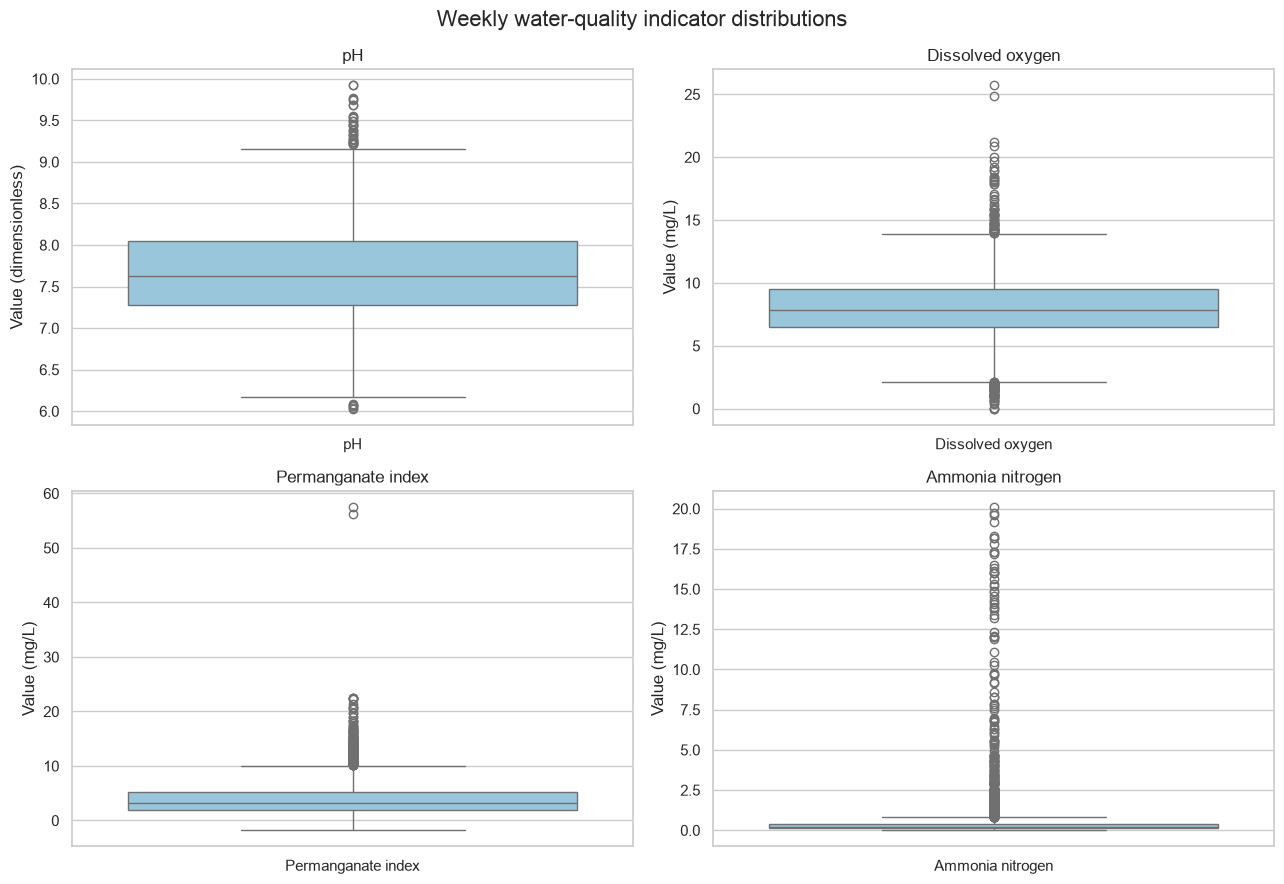

Saved: outputs/figures/indicator_boxplots.png


In [13]:
sns.set_theme(style="whitegrid")
plot_data = cleaned_unique.loc[cleaned_unique["Value"].notna()].copy()
indicators = list(INDICATORS.values())
indicator_order = [item[0] for item in indicators]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, indicator in zip(axes.flat, indicator_order):
    subset = plot_data.loc[plot_data["IndicatorsName"].eq(indicator)]
    sns.boxplot(data=subset, x="IndicatorsName", y="Value", ax=ax, color="#8ecae6")
    unit = subset["Unit"].dropna().iloc[0] if not subset.empty else ""
    ax.set_title(indicator)
    ax.set_xlabel("")
    ax.set_ylabel(f"Value ({unit})")
fig.suptitle("Weekly water-quality indicator distributions", fontsize=16)
fig.tight_layout()
boxplot_path = FIGURE_DIR / "indicator_boxplots.png"
fig.savefig(boxplot_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", boxplot_path.relative_to(PROJECT_DIR))

### 5.6 Construct the Full Dataset

Long format is the primary release because every row has one value and one unit, which is safe for mixed indicators and convenient for visualization and machine learning preprocessing. A teaching-only wide view can be created with `pivot_table`, but the required release remains long format.

**Primary key:** `RecordIdentifier`  
**Metadata key:** (`MonitoringLocationIdentifier`, `IndicatorsName`)  
**Join rule:** join observations to metadata on both metadata-key fields.

In [14]:
dataset_columns = [
    "RecordIdentifier", "MonitoringLocationIdentifier", "MonitoringLocationName",
    "RiverBasin", "RiverName", "SectionContext", "ReportIssue", "ReportWeek",
    "ReportPeriodStart", "ReportPeriodEnd", "SamplingDate", "MeasurementTimestamp",
    "IndicatorsName", "Value", "Unit", "OriginalValue", "QCFlag", "QCAction",
    "WaterQualityClassCurrent", "WaterQualityClassPrevious", "MainPollutants",
    "SourceProvider", "SourcePDF", "PDFPage", "PDFTable", "PDFSourceRow",
    "ExtractionMethod",
]
water_quality_dataset = cleaned_unique[dataset_columns].copy().sort_values(
    ["ReportWeek", "MonitoringLocationIdentifier", "IndicatorsName"]
).reset_index(drop=True)
water_quality_dataset.to_csv(OUTPUT_DIR / "water_quality_dataset.csv", index=False, encoding="utf-8-sig")

wide_preview = water_quality_dataset.pivot_table(
    index=["MonitoringLocationIdentifier", "MonitoringLocationName", "ReportWeek"],
    columns="IndicatorsName", values="Value", aggfunc="first"
).reset_index()
display(wide_preview.head())
print(f"Final long-format rows: {len(water_quality_dataset):,}")

IndicatorsName,MonitoringLocationIdentifier,MonitoringLocationName,ReportWeek,Ammonia nitrogen,Dissolved oxygen,Permanganate index,pH
0,ST-01F82E80EB04,石家庄岗南水库,1,0.06,11.6,2.0,8.70
1,ST-01F82E80EB04,石家庄岗南水库,3,0.04,10.7,2.0,8.22
2,ST-01F82E80EB04,石家庄岗南水库,4,0.04,12.3,2.0,8.61
3,ST-01F82E80EB04,石家庄岗南水库,5,0.04,10.6,1.9,8.01
4,ST-01F82E80EB04,石家庄岗南水库,6,0.04,10.8,1.9,7.86


Final long-format rows: 17,908


### 5.7 Dataset Documentation

The data dictionary describes every field in the final observation table. The README records coverage, extraction decisions, limitations, and reproduction steps.

In [15]:
dictionary_rows = [
    ("RecordIdentifier", "Unique observation identifier", "string", "none", "blank not allowed", "Derived", "Primary key"),
    ("MonitoringLocationIdentifier", "Deterministic station identifier from reported basin, river, and station text", "string", "none", "blank not allowed", "Derived from PDF", "Identity changes if source naming changes"),
    ("MonitoringLocationName", "Monitoring station name as extracted and whitespace-normalized", "string", "none", "blank", "PDF table", "No geographic inference"),
    ("RiverBasin", "River-basin label carried forward from merged PDF cells", "string", "none", "blank", "PDF table", "Review page-boundary carry-forward"),
    ("RiverName", "River name carried forward from merged PDF cells", "string", "none", "blank", "PDF table", "Review page-boundary carry-forward"),
    ("SectionContext", "Reported section context, such as boundary or reservoir context", "string", "none", "blank", "PDF table", "Not used to infer site type"),
    ("ReportIssue", "Weekly report issue number", "integer", "none", "blank", "PDF title", ""),
    ("ReportWeek", "Reported week number", "integer", "week", "blank", "PDF title", "Reporting period, not sample timestamp"),
    ("ReportPeriodStart", "Start date of weekly reporting period", "date", "none", "blank", "PDF narrative", ""),
    ("ReportPeriodEnd", "End date of weekly reporting period", "date", "none", "blank", "PDF narrative", ""),
    ("SamplingDate", "Actual sampling date", "date", "none", "blank", "Not available", "Intentionally missing"),
    ("MeasurementTimestamp", "Actual measurement timestamp", "datetime", "none", "blank", "Not available", "Intentionally missing"),
    ("IndicatorsName", "Standardized water-quality indicator", "string", "none", "blank not allowed", "PDF header", ""),
    ("Value", "Parsed numerical weekly value", "float", "see Unit", "blank", "PDF table", "Retained when flagged"),
    ("Unit", "Measurement unit", "string", "dimensionless or mg/L", "blank", "PDF header plus pH correction", "Never combine unlike units"),
    ("OriginalValue", "Unmodified extracted value token", "string", "source notation", "blank", "PDF table", "Audit field"),
    ("QCFlag", "Quality-control screening result", "string", "none", "blank not allowed", "Derived", "Flags do not prove error"),
    ("QCAction", "Recommended retention/review action", "string", "none", "blank not allowed", "Derived", ""),
    ("WaterQualityClassCurrent", "Reported current-week water-quality class", "string", "class", "blank", "PDF table", "Categorical"),
    ("WaterQualityClassPrevious", "Reported previous-week water-quality class", "string", "class", "blank", "PDF table", "Categorical"),
    ("MainPollutants", "Reported main pollutants", "string", "none", "blank", "PDF table", "Categorical text"),
    ("SourceProvider", "Verified report provider", "string", "none", "blank not allowed", "PDF title page", ""),
    ("SourcePDF", "Source PDF filename", "string", "none", "blank not allowed", "Filesystem", "Provenance"),
    ("PDFPage", "One-based source page number", "integer", "page", "blank not allowed", "Extraction", "Provenance"),
    ("PDFTable", "One-based table number on page", "integer", "table", "blank not allowed", "Extraction", "Provenance"),
    ("PDFSourceRow", "One-based row within extracted table", "integer", "row", "blank not allowed", "Extraction", "Provenance"),
    ("ExtractionMethod", "Software extraction method", "string", "none", "blank not allowed", "Processing", ""),
]
data_dictionary = pd.DataFrame(dictionary_rows, columns=[
    "VariableName", "Definition", "DataType", "Unit", "MissingValueConvention",
    "DataSource", "QualityControlNotes"
])
data_dictionary.to_csv(OUTPUT_DIR / "data_dictionary.csv", index=False, encoding="utf-8-sig")

readme = f"""# Weekly Water-Quality Dataset

## Coverage
- Source reports: {len(pdf_files)} weekly PDF files.
- Report weeks: {min(expected_weeks)}–{max(expected_weeks)} of 2014.
- Final observation rows: {len(water_quality_dataset):,} (reported missing values are retained).

## Source
China National Environmental Monitoring Centre (中国环境监测总站), national key-section water-quality automatic monitoring weekly reports.

## Reproduction
Open `PDF_Data_Cleaning_and_Dataset_Construction.ipynb` from the Date2 directory and run all cells.

## Processing
Tables were extracted with pdfplumber. Repeated headers were removed using integer station serials; merged labels were carried forward; four indicator columns were reshaped to long format; source tokens and PDF provenance were retained; exact duplicate observations were removed only after logging.

## Known limitations
- Weekly periods are report windows, not verified sampling dates or measurement timestamps.
- Monitoring location type, coordinates, and province are not reliably available and remain missing.
- Reports marked partial or failed in `extraction_log.csv` require manual review; compatible rows remain in the release.
- Availability metrics describe weekly-summary coverage in this local report collection, not daily/hourly instrument completeness.
- Statistical outliers are not automatically measurement errors.
"""
(OUTPUT_DIR / "README.md").write_text(readme, encoding="utf-8")
display(data_dictionary.head())

,VariableName,Definition,DataType,Unit,MissingValueConvention,DataSource,QualityControlNotes
0,RecordIdentifier,Unique observation identifier,string,none,blank not allowed,Derived,Primary key
1,MonitoringLocationIdentifier,Deterministic station identifier from reported...,string,none,blank not allowed,Derived from PDF,Identity changes if source naming changes
2,MonitoringLocationName,Monitoring station name as extracted and white...,string,none,blank,PDF table,No geographic inference
3,RiverBasin,River-basin label carried forward from merged ...,string,none,blank,PDF table,Review page-boundary carry-forward
4,RiverName,River name carried forward from merged PDF cells,string,none,blank,PDF table,Review page-boundary carry-forward


### 5.8 Dataset Validation

Validation checks primary keys, date order (including cross-year reporting weeks), units, values, provenance, metadata joins, and agreement between observation records and metadata. Structural inconsistencies are labelled **FAIL** and stop execution. Plausible outliers or reports needing source-page review are labelled **WARNING**, remain in the exported data, and do not invalidate an otherwise consistent release.

In [16]:
qc_report = (
    cleaned_unique.groupby(["QCFlag", "IndicatorsName"], dropna=False)
    .size().rename("RowCount").reset_index()
)
qc_report.to_csv(OUTPUT_DIR / "quality_control_report.csv", index=False, encoding="utf-8-sig")

metadata_keys = set(map(tuple, metadata[["MonitoringLocationIdentifier", "IndicatorsName"]].to_records(index=False)))
observation_keys = set(map(tuple, water_quality_dataset[["MonitoringLocationIdentifier", "IndicatorsName"]].to_records(index=False)))
allowed_units = {"pH": "dimensionless", "Dissolved oxygen": "mg/L",
                 "Permanganate index": "mg/L", "Ammonia nitrogen": "mg/L"}
unit_mismatches = sum(
    water_quality_dataset.apply(lambda r: allowed_units.get(r["IndicatorsName"]) != r["Unit"], axis=1)
)

# Validation has two levels:
# - FAIL: a structural problem that makes the release internally inconsistent.
# - WARNING: a scientifically plausible value or extraction condition that needs review.
validation_checks = [
    ("duplicate_record_identifiers", "FAIL", int(water_quality_dataset["RecordIdentifier"].duplicated().sum()), 0,
     "Primary keys must be unique."),
    ("missing_station_identifiers", "FAIL", int(water_quality_dataset["MonitoringLocationIdentifier"].isna().sum()), 0,
     "Every observation must have a station identifier."),
    ("missing_station_names", "FAIL", int(water_quality_dataset["MonitoringLocationName"].isna().sum()), 0,
     "Every observation must retain its reported station name."),
    ("missing_or_unparsed_report_dates", "FAIL",
     int(water_quality_dataset[["ReportPeriodStart", "ReportPeriodEnd"]].isna().any(axis=1).sum()), 0,
     "Reporting-period dates must be available."),
    ("end_date_before_start_date", "FAIL",
     int((water_quality_dataset["ReportPeriodEnd"] < water_quality_dataset["ReportPeriodStart"]).sum()), 0,
     "Cross-year weeks must use the preceding year for a December start date."),
    ("indicator_unit_mismatches", "FAIL", int(unit_mismatches), 0,
     "Each indicator must use its declared unit."),
    ("missing_source_pdf", "FAIL", int(water_quality_dataset["SourcePDF"].isna().sum()), 0,
     "Every observation must retain PDF provenance."),
    ("observation_keys_missing_from_metadata", "FAIL", len(observation_keys - metadata_keys), 0,
     "Every observation station-indicator key must exist in metadata."),
    ("metadata_keys_without_observations", "FAIL", len(metadata_keys - observation_keys), 0,
     "Every metadata key must reference at least one observation."),
    ("duplicate_report_weeks", "FAIL",
     int(extraction_log[["ReportYear", "ReportWeek"]].duplicated().sum()), 0,
     "Only one source report is expected for each reporting week."),
    ("unlogged_pdf_files", "FAIL", int(len(pdf_files) - extraction_log["SourcePDF"].nunique()), 0,
     "Every discovered PDF must appear exactly once in the extraction log."),
    ("range_review_rows", "WARNING", int(water_quality_dataset["QCFlag"].eq("range_review").sum()), 0,
     "Retain and inspect values outside the broad screening range; they are not automatically errors."),
    ("reports_requiring_manual_review", "WARNING",
     int(extraction_log["ExtractionStatus"].ne("success").sum()), 0,
     "Partial or failed extraction requires source-page review."),
]
dataset_validation = pd.DataFrame(
    validation_checks,
    columns=["Check", "Severity", "ObservedCount", "ExpectedCount", "Interpretation"],
)
dataset_validation["Status"] = np.select(
    [
        dataset_validation["ObservedCount"].eq(dataset_validation["ExpectedCount"]),
        dataset_validation["Severity"].eq("WARNING"),
    ],
    ["PASS", "WARNING"],
    default="FAIL",
)
dataset_validation.to_csv(OUTPUT_DIR / "dataset_validation.csv", index=False, encoding="utf-8-sig")

hard_failures = dataset_validation.query("Status == 'FAIL'")
if not hard_failures.empty:
    raise AssertionError(
        "Structural dataset validation failed:\n" +
        hard_failures[["Check", "ObservedCount", "ExpectedCount"]].to_string(index=False)
    )

display(dataset_validation)
display(qc_report)
print("Structural validation passed. WARNING rows remain visible for scientific review.")

,Check,Severity,ObservedCount,ExpectedCount,Interpretation,Status
0,duplicate_record_identifiers,FAIL,0,0,Primary keys must be unique.,PASS
1,missing_station_identifiers,FAIL,0,0,Every observation must have a station identifier.,PASS
2,missing_station_names,FAIL,0,0,Every observation must retain its reported sta...,PASS
3,missing_or_unparsed_report_dates,FAIL,0,0,Reporting-period dates must be available.,PASS
4,end_date_before_start_date,FAIL,0,0,Cross-year weeks must use the preceding year f...,PASS
5,indicator_unit_mismatches,FAIL,0,0,Each indicator must use its declared unit.,PASS
6,missing_source_pdf,FAIL,0,0,Every observation must retain PDF provenance.,PASS
7,observation_keys_missing_from_metadata,FAIL,0,0,Every observation station-indicator key must e...,PASS
8,metadata_keys_without_observations,FAIL,0,0,Every metadata key must reference at least one...,PASS
9,duplicate_report_weeks,FAIL,0,0,Only one source report is expected for each re...,PASS


,QCFlag,IndicatorsName,RowCount
0,pass,Ammonia nitrogen,4333
1,pass,Dissolved oxygen,4330
2,pass,Permanganate index,4338
3,pass,pH,4337
4,range_review,Permanganate index,1
5,reported_missing,Ammonia nitrogen,144
6,reported_missing,Dissolved oxygen,147
7,reported_missing,Permanganate index,138
8,reported_missing,pH,140


Structural validation passed. WARNING rows remain visible for scientific review.


<div class="alert alert-block alert-info" style="border:1px solid #bce8f1; background:#d9edf7; padding:1em; border-radius:4px;">
  <p style="font-size:24px; margin:0;">Representative source-value verification</p>
</div>

The checks below were transcribed from the first rows of the week 14 and week 15 PDF tables. They provide a reproducible spot check of table extraction and value parsing.

In [17]:
manual_checks = pd.DataFrame([
    (14, "吉林溪浪口", "pH", 6.93),
    (14, "吉林溪浪口", "Dissolved oxygen", 6.91),
    (14, "吉林溪浪口", "Permanganate index", 3.60),
    (14, "吉林溪浪口", "Ammonia nitrogen", 0.43),
    (15, "吉林溪浪口", "pH", 6.83),
    (15, "长春松花江村", "Dissolved oxygen", 9.60),
], columns=["ReportWeek", "MonitoringLocationName", "IndicatorsName", "ExpectedValue"])

verification = manual_checks.merge(
    water_quality_dataset[["ReportWeek", "MonitoringLocationName", "IndicatorsName", "Value", "SourcePDF", "PDFPage"]],
    on=["ReportWeek", "MonitoringLocationName", "IndicatorsName"], how="left"
)
verification["MatchesPDF"] = np.isclose(verification["Value"], verification["ExpectedValue"], equal_nan=False)
assert verification["MatchesPDF"].all(), "At least one representative value does not match the source PDF."
verification.to_csv(OUTPUT_DIR / "representative_value_verification.csv", index=False, encoding="utf-8-sig")
display(verification)
print("All representative source-value checks passed.")

,ReportWeek,MonitoringLocationName,IndicatorsName,ExpectedValue,Value,SourcePDF,PDFPage,MatchesPDF
0,14,吉林溪浪口,pH,6.93,6.93,2014年第14期.pdf,2,True
1,14,吉林溪浪口,Dissolved oxygen,6.91,6.91,2014年第14期.pdf,2,True
2,14,吉林溪浪口,Permanganate index,3.60,3.60,2014年第14期.pdf,2,True
3,14,吉林溪浪口,Ammonia nitrogen,0.43,0.43,2014年第14期.pdf,2,True
4,15,吉林溪浪口,pH,6.83,6.83,2014年第15期.pdf,2,True
5,15,长春松花江村,Dissolved oxygen,9.60,9.60,2014年第15期.pdf,2,True


All representative source-value checks passed.



<div class="alert alert-block alert-info" style="border:1px solid #bce8f1; background:#d9edf7; padding:1em; border-radius:4px;">
  <p style="font-size:24px; margin:0;">Group Competition: From Clean Data to Reproducible Research</p>
</div>

You have now transformed messy environmental reports into a structured dataset.

The next challenge is not simply to write more code. Your team must build a data product that another scientist can understand, review, reproduce, and reuse.

> **Your task is not to produce the most code. Your task is to produce the most defensible data product.**

All seven teams use the same CNEMC-derived source dataset, but each team develops a different research-data product and addresses a different scientific or data-engineering question.

The competition follows **Build → Review → Reproduce → Release**. AI tools are allowed, but human verification is required. Scientific reasoning and reproducibility matter more than code complexity.



### Seven Group Missions

| Group | Theme | Core Question |
|:---:|---|---|
| 1 | Dissolved Oxygen | Which DO records are reliable enough for temporal and cross-station comparison? |
| 2 | Ammonia Nitrogen | Can stations be compared fairly despite uneven monitoring coverage? |
| 3 | Station Comparison | When are two monitoring stations sufficiently comparable? |
| 4 | Temporal Coverage | Which station–indicator records are suitable for temporal analysis? |
| 5 | High-Quality Dataset | How should a defensible “high-quality” analysis dataset be defined? |
| 6 | Multivariate Dataset | How much completeness should be traded for retaining more variables? |
| 7 | QC & Provenance | Can final values be traced back to their source and processing history? |

> Open your assigned group folder under `group_challenges/` and start with `START_HERE.md`.

The detailed challenge specification remains in the same folder as `challenge_brief.md`. This notebook provides only the common competition framework.



<div class="alert alert-block alert-warning" style="border:1px solid #faebcc; background:#fcf8e3; padding:1em; border-radius:4px;">
  <p style="font-size:24px; margin:0 0 0.5em 0;">Competition Rules</p>
  <ol style="margin-bottom:0;">
    <li><strong>AI tools are allowed.</strong> Teams may use ChatGPT, Codex, or similar AI tools.</li>
    <li><strong>Every decision must be defendable.</strong> Understand and explain all filtering rules, transformations, metrics, and outputs.</li>
    <li><strong>AI-generated output is not automatically correct.</strong> Verify suggestions against the source data and project documentation.</li>
    <li><strong>Reproducibility matters more than complexity.</strong> A simple, reproducible workflow is better than an elaborate workflow that cannot be explained.</li>
    <li><strong>Do not fabricate missing information.</strong> Do not invent coordinates, metadata, observations, dates, station properties, or environmental explanations.</li>
    <li><strong>Use relative paths whenever possible.</strong></li>
    <li><strong>Do not create a real Zenodo DOI</strong> for this classroom exercise.</li>
    <li><strong>Do not publicly upload the complete CNEMC-derived classroom dataset</strong> unless redistribution permission has been explicitly established.</li>
    <li><strong>Be prepared for a live instructor challenge.</strong> During the oral defense, the instructor may change one analytical assumption and ask how the result changes.</li>
  </ol>
</div>



### Team Deliverables

#### 1. A GitHub/Gitee-ready repository

Where appropriate, include a notebook and/or analysis scripts, a README, requirements or environment information, `.gitignore`, relative paths, clear input/output instructions, and an **AI Assistance** statement. Do **not** upload the full environmental dataset to GitHub or Gitee.

#### 2. A group-specific data product

Depending on the assigned mission, this may be a DO analysis-ready dataset, ammonia-nitrogen comparison dataset, station-comparability product, temporal-coverage dataset, high-quality analysis dataset, multivariate feature table, or provenance audit.

#### 3. Documentation

Include metadata, a data dictionary, assumptions, known limitations, and provenance information.

#### 4. AI Verification Log

Document at least one AI-assisted suggestion and your independent check:

```text
AI suggestion:
...

How we checked it:
...

Accepted / rejected:
...
```



## Live Peer-Review Assignment

Each team will review one other team, and each team will also be reviewed by exactly one other team. The assignment will be generated live in class.

The random draw creates **one complete seven-team review cycle**: no team reviews itself, every team reviews exactly one team, and every team receives exactly one review.

> During class, keep `USE_FIXED_SEED = False` for a live random draw. After the final assignment is accepted, optionally switch to a fixed seed or save the assignment so it can be reproduced later.

To **draw again**, simply rerun the next code cell before the assignment is finalized. No additional widget or GUI dependency is required.


In [2]:

# Instructor controls
USE_FIXED_SEED = False
RANDOM_SEED = 42

import random
import pandas as pd
try:
    from IPython.display import display
except ImportError:  # Allows the logic to run outside Jupyter as well.
    display = print

groups = [f"Group {number}" for number in range(1, 8)]

# Use an independent random-number generator so this cell does not change
# random behavior elsewhere in the notebook.
rng = random.Random(RANDOM_SEED) if USE_FIXED_SEED else random.Random()
review_cycle = groups.copy()
rng.shuffle(review_cycle)

# Connecting every team to the next team creates one complete cycle.
assignment_pairs = [
    (reviewer, review_cycle[(index + 1) % len(review_cycle)])
    for index, reviewer in enumerate(review_cycle)
]

review_assignment = pd.DataFrame(
    assignment_pairs,
    columns=["Reviewer", "Reviews"],
)

reviews_lookup = dict(assignment_pairs)
reviewed_by_lookup = {reviewed: reviewer for reviewer, reviewed in assignment_pairs}
review_assignment_by_team = pd.DataFrame({
    "Team": groups,
    "Reviews": [reviews_lookup[team] for team in groups],
    "Reviewed by": [reviewed_by_lookup[team] for team in groups],
})

# Transparent checks of all assignment rules.
assert len(review_assignment) == 7
assert (review_assignment["Reviewer"] != review_assignment["Reviews"]).all()
assert review_assignment["Reviewer"].nunique() == 7
assert review_assignment["Reviews"].nunique() == 7

print("Reviewer → reviewed team")
display(review_assignment)

print("Team-centered view")
display(review_assignment_by_team)

review_chain = " → ".join(review_cycle + [review_cycle[0]])
print("Review cycle:")
print(review_chain)


Reviewer → reviewed team


,Reviewer,Reviews
0,Group 3,Group 4
1,Group 4,Group 6
2,Group 6,Group 1
3,Group 1,Group 5
4,Group 5,Group 2
5,Group 2,Group 7
6,Group 7,Group 3


Team-centered view


,Team,Reviews,Reviewed by
0,Group 1,Group 5,Group 6
1,Group 2,Group 7,Group 5
2,Group 3,Group 4,Group 7
3,Group 4,Group 6,Group 3
4,Group 5,Group 2,Group 1
5,Group 6,Group 1,Group 4
6,Group 7,Group 3,Group 2


Review cycle:
Group 3 → Group 4 → Group 6 → Group 1 → Group 5 → Group 2 → Group 7 → Group 3


In [ ]:

# Run this cell only after the class accepts the displayed assignment.
from pathlib import Path

OVERWRITE_EXISTING_ASSIGNMENT = False
SAVE_MARKDOWN_COPY = True

assignment_to_save = review_assignment_by_team.rename(
    columns={"Reviewed by": "Reviewed_by"}
)

# PROJECT_DIR is configured near the beginning of this notebook as Date2.
review_output_dir = PROJECT_DIR / "group_challenges" / "instructor"
review_output_dir.mkdir(parents=True, exist_ok=True)

csv_path = review_output_dir / "current_review_assignment.csv"
markdown_path = review_output_dir / "current_review_assignment.md"
paths_to_write = [csv_path] + ([markdown_path] if SAVE_MARKDOWN_COPY else [])

existing_paths = [path for path in paths_to_write if path.exists()]
if existing_paths and not OVERWRITE_EXISTING_ASSIGNMENT:
    existing_names = ", ".join(path.name for path in existing_paths)
    raise FileExistsError(
        f"Assignment not saved because these files already exist: {existing_names}. "
        "Set OVERWRITE_EXISTING_ASSIGNMENT = True only after confirming replacement."
    )

assignment_to_save.to_csv(csv_path, index=False, encoding="utf-8-sig")

if SAVE_MARKDOWN_COPY:
    lines = [
        "# Current Peer-Review Assignment",
        "",
        "| Team | Reviews | Reviewed_by |",
        "|---|---|---|",
    ]
    lines.extend(
        f"| {row.Team} | {row.Reviews} | {row.Reviewed_by} |"
        for row in assignment_to_save.itertuples(index=False)
    )
    markdown_path.write_text("\n".join(lines) + "\n", encoding="utf-8")

print(f"Saved accepted assignment: {csv_path.relative_to(PROJECT_DIR)}")
if SAVE_MARKDOWN_COPY:
    print(f"Saved projection-friendly copy: {markdown_path.relative_to(PROJECT_DIR)}")


<div class="alert alert-block alert-info" style="border:1px solid #bce8f1; background:#d9edf7; padding:1em; border-radius:4px;">
  <p style="font-size:24px; margin:0;">Extension: Try to make it as a skill</p>
</div>